# 05. Final model: LightGBM residual

Verdict: LightGBM on the residual (load - RTE), chosen on the validation folds, beats RTE raw on all three scopes. Its intervals are too narrow in winter and on cold days. MAE test: 910 MW vs RTE raw 1,439 MW (-36.8 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.

## 1. Setup

Same frame as 04_lightgbm. This notebook covers question 2 (uncertainty, when it fails) and prepares question 3
(deployment). Hyperparameters and the 2019 start of LightGBM + RTE come from 04.

In [1]:
import sys
sys.path.insert(0, "../src")

from datetime import date, timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from watt_forecast.data_preprocessing import load_dataset, save_predictions
from watt_forecast.features import make_features, feature_cols, french_holidays
from watt_forecast.metrics import compute_metrics, evaluate, scorecard, COLD_DAY_C, PEAK_HOURS
from watt_forecast.models.gbm import (
    fit_lgbm, predict, fit_residual, predict_residual, walk_forward_predictions, conformal_intervals,
)

TRAIN_END = date(2025, 6, 30)
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)
FOLDS = [
    (date(2024, 7, 1), date(2024, 9, 30)),
    (date(2024, 10, 1), date(2024, 12, 31)),
    (date(2025, 1, 1), date(2025, 3, 31)),
    (date(2025, 4, 1), date(2025, 6, 30)),
]
FOLD_NAMES = ["Q3_2024", "Q4_2024", "Q1_2025", "Q2_2025"]
VALID_START, VALID_END = FOLDS[0][0], FOLDS[-1][1]

PARAMS = dict(num_leaves=31, learning_rate=0.05, n_estimators=500)  # chosen in 04_lightgbm
LGBM_START = date(2019, 1, 1)  # chosen in 04_lightgbm

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.figsize"] = (12, 4)

In [2]:
df = load_dataset()
features = make_features(df, "persistence", with_rte=True)
assert features.height == df.height and (features["datetime_utc"] == df["datetime_utc"]).all(), "same rows"

## 2. Model

Two candidates, RTE raw as reference:

- LightGBM + RTE: the 04 model.
- LightGBM residual: target = load - RTE, forecast = RTE + correction. Peaks come from RTE, no extrapolation needed.

### Training period of the residual model

In [3]:
valid = df.filter(pl.col("date").is_between(VALID_START, VALID_END)).select(
    "datetime_utc", "date", "hour", "target", "temperature_c", "rte_forecast_j1_mw"
)


def add_walk_forward(table, name, start, **kwargs):
    """Walk-forward predictions of a LightGBM model trained from `start`, joined as column `name`."""
    preds = walk_forward_predictions(features.filter(pl.col("date") >= start), FOLDS, PARAMS, **kwargs)
    return table.join(preds.select("datetime_utc", pl.col("pred").alias(name)), on="datetime_utc", how="left", maintain_order="left")


def fold_mae(table, col):
    return [compute_metrics(table.filter(pl.col("date").is_between(a, b)), col)["MAE"] for a, b in FOLDS]


residual_starts = {"since 2019": date(2019, 1, 1), "since 2023": date(2023, 1, 1)}
for name, start in residual_starts.items():
    valid = add_walk_forward(valid, f"residual_{start.year}", start, fit=fit_residual, predict_fn=predict_residual)

start_choice = pl.DataFrame(
    [{"train": name, **dict(zip(FOLD_NAMES, fold_mae(valid, f"residual_{start.year}"))), "mean": np.mean(fold_mae(valid, f"residual_{start.year}"))}
     for name, start in residual_starts.items()]
).sort("mean")
RESIDUAL_START = residual_starts[start_choice["train"][0]]
kept, dropped = RESIDUAL_START.year, residual_starts[start_choice["train"][1]].year
valid = valid.rename({f"residual_{kept}": "lgbm_residual"}).drop(f"residual_{dropped}")
print("residual model trained", start_choice["train"][0])
start_choice.with_columns(pl.exclude("train").round(0))

residual model trained since 2019


train,Q3_2024,Q4_2024,Q1_2025,Q2_2025,mean
str,f64,f64,f64,f64,f64
"""since 2019""",653.0,968.0,999.0,819.0,860.0
"""since 2023""",619.0,1093.0,1119.0,708.0,885.0


Not what we expected: 2019 wins here too (860 vs 885 MW). 2023 is better on the mild folds but much worse in winter.
We keep 2019.

### Choice of the final model, on the folds only

Rule fixed beforehand: best mean fold MAE, and if within 1 %, best MAE on cold evening peaks of the validation period.

In [4]:
valid = add_walk_forward(valid, "lgbm_rte", LGBM_START)
assert valid.height == (VALID_END - VALID_START + timedelta(days=1)).days * 24, "one row per validation hour"

candidates = {"LightGBM + RTE": "lgbm_rte", "LightGBM residual": "lgbm_residual"}


def cold_peak_mae(table, col):
    """MAE on the evening peaks of cold days of the validation period."""
    return evaluate(table, col).filter(pl.col("scope") == "evening_peak_18-20h_cold_days")["MAE"].item()


cv_table = pl.DataFrame(
    [{"model": name, **dict(zip(FOLD_NAMES, fold_mae(valid, col))), "mean": np.mean(fold_mae(valid, col)),
      "std": np.std(fold_mae(valid, col)), "cold_evening_peaks": cold_peak_mae(valid, col)}
     for name, col in {**candidates, "RTE raw": "rte_forecast_j1_mw"}.items()]
).sort("mean")

ranked = cv_table.filter(pl.col("model").is_in(list(candidates)))
gap = 100 * (ranked["mean"][1] - ranked["mean"][0]) / ranked["mean"][0]
if gap < 1:
    FINAL = ranked.sort("cold_evening_peaks")["model"][0]
    print(f"mean MAEs {gap:.2f} % apart (< 1 %): final model = best on the cold evening peaks of the validation:", FINAL)
else:
    FINAL = ranked["model"][0]
    print(f"final model = best mean MAE on the folds ({gap:.2f} % ahead):", FINAL)
FINAL_COL = candidates[FINAL]
cv_table.with_columns(pl.exclude("model").round(0))

mean MAEs 0.09 % apart (< 1 %): final model = best on the cold evening peaks of the validation: LightGBM residual


model,Q3_2024,Q4_2024,Q1_2025,Q2_2025,mean,std,cold_evening_peaks
str,f64,f64,f64,f64,f64,f64,f64
"""LightGBM residual""",653.0,968.0,999.0,819.0,860.0,137.0,1478.0
"""LightGBM + RTE""",620.0,982.0,1027.0,813.0,860.0,160.0,1557.0
"""RTE raw""",1140.0,1381.0,1369.0,1560.0,1362.0,149.0,1822.0


Tie on the folds (860 MW each, 0.09 % apart, vs 1,362 MW for RTE raw). On cold evening peaks the residual model wins
(1,478 vs 1,557 MW) and it's a bit more stable (std 137 vs 160 MW). Final model: LightGBM residual.

### Test year

In [5]:
def fit_and_predict(fit, predict_fn, start):
    """Train from `start` to TRAIN_END, predict the test year."""
    cols = feature_cols(features)
    train = features.filter(pl.col("date").is_between(start, TRAIN_END)).drop_nulls("lag_336")
    test_rows = features.filter(pl.col("date").is_between(TEST_START, TEST_END))
    assert train["date"].max() < test_rows["date"].min(), "training rows must come before the test"
    return predict_fn(fit(train.select(cols), train["target"], PARAMS), test_rows.select(cols))


test = df.filter(pl.col("date").is_between(TEST_START, TEST_END)).with_columns(
    pl.Series("lgbm_rte", fit_and_predict(fit_lgbm, predict, LGBM_START)),
    pl.Series("lgbm_residual", fit_and_predict(fit_residual, predict_residual, RESIDUAL_START)).fill_nan(None),
)
assert test.height == 365 * 24, "the test period should have 8,760 hours"

forecasts = {"RTE raw": "rte_forecast_j1_mw", **candidates}

In [6]:
# Test forecasts of this notebook, read by 06_comparison (LightGBM + RTE is saved by 04, RTE raw by 01)
save_predictions(test, {"LightGBM residual": "lgbm_residual"}, "05_final_model")

### Prediction intervals

Split conformal: per-hour quantiles of the validation errors (10-90 % for the 80 % interval, 2.5-97.5 % for 95 %).

In [7]:
valid = valid.with_columns((pl.col("target") - pl.col(FINAL_COL)).alias("residual"))
intervals = {level: conformal_intervals(valid["residual"], valid["hour"], 1 - level) for level in (0.8, 0.95)}
assert all(t.height == 24 for t in intervals.values()), "one interval per local hour"

In [8]:
SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

test = test.with_columns(
    pl.col("month").replace_strict(SEASONS).alias("season"),
    (pl.col("temperature_c").mean().over("date") < COLD_DAY_C).alias("cold_day"),  # observed: for evaluation only
    pl.col("hour").is_in(PEAK_HOURS).alias("evening_peak"),
)


def add_interval(table, bounds, level, keys=("hour",)):
    """Columns lo/hi of the interval around the final forecast."""
    tag = int(level * 100)
    return table.join(bounds.select(*keys, "q_low", "q_high"), on=list(keys), how="left", maintain_order="left").with_columns(
        (pl.col(FINAL_COL) + pl.col("q_low")).alias(f"lo{tag}"),
        (pl.col(FINAL_COL) + pl.col("q_high")).alias(f"hi{tag}"),
    ).drop("q_low", "q_high")


def coverage_table(table):
    """Coverage and mean width of the 80 % and 95 % intervals on several scopes."""
    scopes = {
        "global": pl.lit(True),
        **{season: pl.col("season") == season for season in ["summer", "autumn", "winter", "spring"]},
        "cold days": pl.col("cold_day"),
        "evening peak 18-20h": pl.col("evening_peak"),
        "evening peak, cold days": pl.col("evening_peak") & pl.col("cold_day"),
    }
    rows = []
    for name, condition in scopes.items():
        part = table.filter(condition).drop_nulls(FINAL_COL)
        row = {"scope": name, "hours": part.height}
        for tag in (80, 95):
            inside = part["target"].is_between(part[f"lo{tag}"], part[f"hi{tag}"])
            row[f"coverage_{tag}_%"] = 100 * inside.mean()
            row[f"width_{tag}_(MW)"] = (part[f"hi{tag}"] - part[f"lo{tag}"]).mean()
        rows.append(row)
    return pl.DataFrame(rows)


test = add_interval(add_interval(test, intervals[0.8], 0.8), intervals[0.95], 0.95)
coverage_by_hour = coverage_table(test)

In [9]:
# Prediction intervals of the final model, read by 07_executive_summary (not by 06_comparison)
save_predictions(test, {tag: tag for tag in ("lo80", "hi80", "lo95", "hi95")}, "05_intervals")

## 3. Results vs benchmark

In [10]:
scorecard(test, forecasts)

forecast,global,evening_peak_18-20h,evening_peak_cold_days,vs_reference_(%)
str,f64,f64,f64,f64
"""RTE raw""",1439.0,1348.0,2307.0,0.0
"""LightGBM + RTE""",908.0,984.0,2010.0,-36.9
"""LightGBM residual""",910.0,987.0,1906.0,-36.8


In [11]:
coverage_by_hour.filter(pl.col("scope").is_in(["global", "winter", "cold days", "evening peak, cold days"])).with_columns(
    pl.exclude("scope", "hours").round(0)
)

scope,hours,coverage_80_%,width_80_(MW),coverage_95_%,width_95_(MW)
str,i64,f64,f64,f64,f64
"""global""",8759,76.0,2378.0,94.0,4244.0
"""winter""",2160,61.0,2378.0,88.0,4244.0
"""cold days""",648,55.0,2378.0,82.0,4244.0
"""evening peak, cold days""",81,51.0,2748.0,73.0,4608.0


What we see. Again almost a tie on average (908 and 910 MW, about 37 % below RTE raw), with the residual model ahead
on cold evening peaks (1,906 vs 2,010 MW). Coverage is 76 % and 94 % overall, but only 61 % and 88 % in winter, 55 % and
82 % on cold days, 51 % and 73 % on cold evening peaks.

## 4. Where it fails

A cold week: 5 to 11 January 2026.

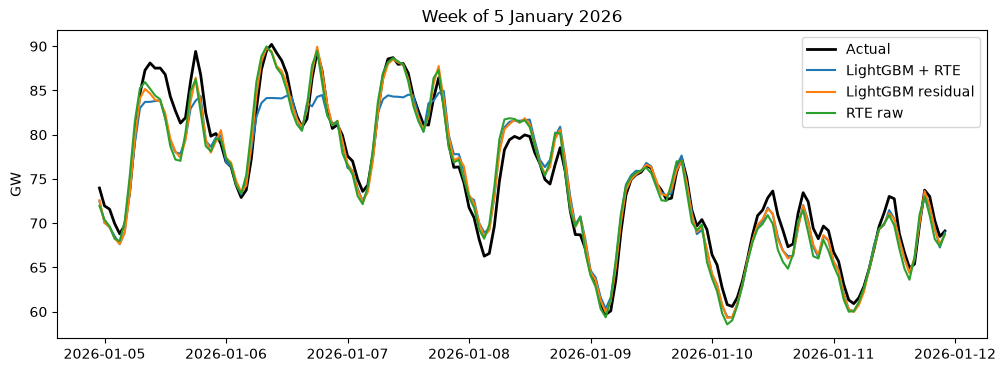

Highest hourly load of the week (GW):
{'Actual': 90.2, 'LightGBM + RTE': 85.0, 'LightGBM residual': 90.0, 'RTE raw': 90.0}


In [12]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["datetime_local"], week["target"] / 1000, color="k", lw=2, label="Actual")
plt.plot(week["datetime_local"], week["lgbm_rte"] / 1000, label="LightGBM + RTE")
plt.plot(week["datetime_local"], week["lgbm_residual"] / 1000, label="LightGBM residual")
plt.plot(week["datetime_local"], week["rte_forecast_j1_mw"] / 1000, label="RTE raw")
plt.title("Week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

print("Highest hourly load of the week (GW):")
print({name: round(week[col].max() / 1000, 1) for name, col in
       {"Actual": "target", "LightGBM + RTE": "lgbm_rte", "LightGBM residual": "lgbm_residual",
        "RTE raw": "rte_forecast_j1_mw"}.items()})

The peaks aren't cut anymore (90.0 GW for an actual 90.2 GW, vs 85.0 GW for LightGBM + RTE). But it misses the same
hours as RTE: the morning of 5 January and all of 8 January.

## 5. Conclusion

- Question 1. Yes, by correcting RTE. LightGBM residual gets 910 MW on the test (-36.8 % vs 1,439 MW), and
  1,906 vs 2,307 MW on cold evening peaks.
- Question 2. Intervals are about 2.4 GW (80 %) and 4.2 GW (95 %) wide, covering 76 % and 94 % of test hours but
  only 51 % and 73 % on cold evening peaks. The model fails when RTE fails.
- Next. Deploy LightGBM residual with wider cold-day intervals, after checking the risks in A.9.

## Appendix

### A.1 Conformal quantiles by hour

In [13]:
intervals[0.8].join(intervals[0.95], on="hour", suffix="_95").with_columns(pl.exclude("hour", "n", "n_95").round(0))

hour,q_low,q_high,n,q_low_95,q_high_95,n_95
i8,f64,f64,u32,f64,f64,u32
0,-267.0,1587.0,365,-862.0,2481.0,365
1,-409.0,1422.0,365,-1186.0,2306.0,365
2,-581.0,1266.0,364,-1402.0,2032.0,364
3,-485.0,1372.0,365,-1172.0,2282.0,365
4,-634.0,1209.0,365,-1395.0,2226.0,365
5,-940.0,1036.0,365,-1584.0,2129.0,365
6,-1403.0,832.0,365,-2245.0,2062.0,365
7,-1413.0,979.0,365,-2279.0,2067.0,365
8,-1261.0,1303.0,365,-2193.0,2437.0,365


### A.2 Coverage on all scopes

In [14]:
coverage_by_hour.with_columns(pl.exclude("scope", "hours").round(0))

scope,hours,coverage_80_%,width_80_(MW),coverage_95_%,width_95_(MW)
str,i64,f64,f64,f64,f64
"""global""",8759,76.0,2378.0,94.0,4244.0
"""summer""",2208,84.0,2378.0,97.0,4244.0
"""autumn""",2184,81.0,2378.0,96.0,4244.0
"""winter""",2160,61.0,2378.0,88.0,4244.0
"""spring""",2207,77.0,2378.0,96.0,4244.0
"""cold days""",648,55.0,2378.0,82.0,4244.0
"""evening peak 18-20h""",1095,75.0,2748.0,93.0,4608.0
"""evening peak, cold days""",81,51.0,2748.0,73.0,4608.0


Fine in summer and autumn (84 % and 81 % for the 80 % interval), too low in the cold. The width depends only on the
hour, not on season or temperature, so the intervals are narrowest where errors cost most.

### A.3 All metrics and bias on the test year

In [15]:
results = pl.concat(
    [evaluate(test, col).with_columns(pl.lit(name).alias("forecast")) for name, col in forecasts.items()]
)
# Bias (forecast - actual) on the same scopes
results.pivot(on="scope", index="forecast", values="bias").with_columns(pl.exclude("forecast").round(0))

forecast,global,evening_peak_18-20h,evening_peak_18-20h_cold_days
str,f64,f64,f64
"""RTE raw""",-1086.0,-850.0,-2004.0
"""LightGBM + RTE""",-414.0,-279.0,-1888.0
"""LightGBM residual""",-420.0,-264.0,-1689.0


Both models keep about -420 MW of bias overall. The residual one is less biased on cold evening peaks (-1,689 vs
-1,888 MW). RTE raw: -1,086 MW on average, -2,004 MW on cold evening peaks.

### A.4 Intervals by hour and by cold / not cold

"Cold at the cutoff" = mean temperature of T-2 below 5 °C, so it's known at 12:00.

In [16]:
cold_known = (
    df.group_by("date").agg(pl.col("temperature_c").mean())
    .sort("date")
    .with_columns((pl.col("temperature_c").shift(2) < COLD_DAY_C).fill_null(False).alias("cold_at_cutoff"))
    .select("date", "cold_at_cutoff")
)
valid = valid.join(cold_known, on="date", how="left", maintain_order="left")
test = test.join(cold_known, on="date", how="left", maintain_order="left")
print("validation days cold at the cutoff:", valid.filter(pl.col("cold_at_cutoff"))["date"].n_unique(),
      "| test days:", test.filter(pl.col("cold_at_cutoff"))["date"].n_unique())

intervals_cold = {
    level: conformal_intervals(valid["residual"], valid["hour"], 1 - level, cold_valid=valid["cold_at_cutoff"]).rename({"cold": "cold_at_cutoff"})
    for level in (0.8, 0.95)
}
test_cold = test.drop("lo80", "hi80", "lo95", "hi95")
for level, bounds in intervals_cold.items():
    test_cold = add_interval(test_cold, bounds, level, keys=("hour", "cold_at_cutoff"))

comparison = coverage_by_hour.select("scope", "hours", pl.col("coverage_80_%", "width_80_(MW)", "coverage_95_%").name.suffix("_|_by_hour")).join(
    coverage_table(test_cold).select("scope", pl.col("coverage_80_%", "width_80_(MW)", "coverage_95_%").name.suffix("_|_hour_x_cold")),
    on="scope",
)
comparison.with_columns(pl.exclude("scope", "hours").round(0))

validation days cold at the cutoff: 43 | test days: 27


scope,hours,coverage_80_%_|_by_hour,width_80_(MW)_|_by_hour,coverage_95_%_|_by_hour,coverage_80_%_|_hour_x_cold,width_80_(MW)_|_hour_x_cold,coverage_95_%_|_hour_x_cold
str,i64,f64,f64,f64,f64,f64,f64
"""global""",8759,76.0,2378.0,94.0,75.0,2304.0,93.0
"""summer""",2208,84.0,2378.0,97.0,82.0,2179.0,95.0
"""autumn""",2184,81.0,2378.0,96.0,79.0,2291.0,95.0
"""winter""",2160,61.0,2378.0,88.0,63.0,2573.0,87.0
"""spring""",2207,77.0,2378.0,96.0,74.0,2180.0,93.0
"""cold days""",648,55.0,2378.0,82.0,65.0,3179.0,85.0
"""evening peak 18-20h""",1095,75.0,2748.0,93.0,74.0,2716.0,93.0
"""evening peak, cold days""",81,51.0,2748.0,73.0,53.0,3207.0,80.0


Helps a bit: 80 % coverage on cold days goes from 55 % to 65 % (width 3.2 GW vs 2.4 GW), global 76 % to 75 %. Still
53 % on cold evening peaks. T-2 is a poor proxy and there are only 43 cold days in validation. A safety margin, or
regimes based on RTE's forecast level, would probably work better.

### A.5 The 80 % interval in the cold week

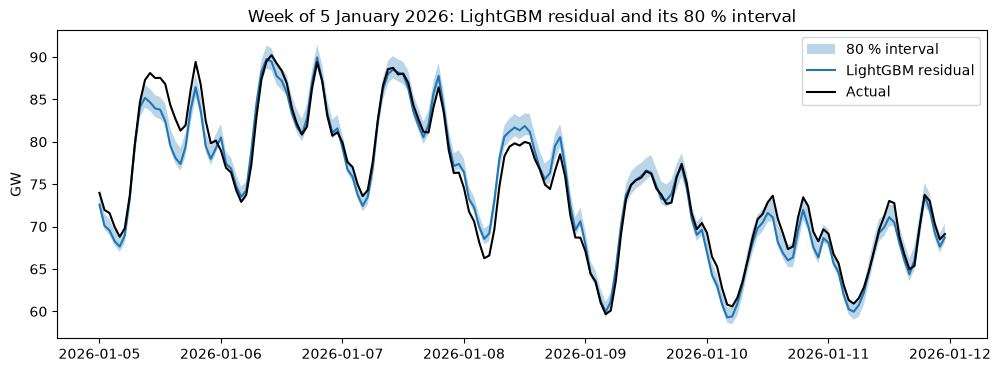

In [17]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.fill_between(week["datetime_local"], week["lo80"] / 1000, week["hi80"] / 1000, alpha=0.3, label="80 % interval")
plt.plot(week["datetime_local"], week[FINAL_COL] / 1000, label=FINAL)
plt.plot(week["datetime_local"], week["target"] / 1000, color="k", label="Actual")
plt.title(f"Week of 5 January 2026: {FINAL} and its 80 % interval")
plt.ylabel("GW")
plt.legend()
plt.show()

Mostly inside the band. Misses are RTE's misses: 5 January morning, all of 8 January, 10 January afternoon.

### A.6 The 15 worst days of the test year

In [18]:
holidays = french_holidays(range(2019, 2028))
days = (
    df.group_by("date")
    .agg(pl.col("temperature_c").mean().alias("temp_(°C)"), pl.len().alias("n_hours"))
    .sort("date")
    .with_columns(
        (pl.col("temp_(°C)") - pl.col("temp_(°C)").shift(1)).alias("temp_change"),
        pl.col("date").dt.strftime("%a").alias("weekday"),
        pl.col("date").is_in(holidays).alias("holiday"),
        pl.col("date").dt.offset_by("1d").is_in(holidays).alias("day_before_hol."),
        pl.col("date").dt.offset_by("-1d").is_in(holidays).alias("day_after_hol."),
        # bridge: a Monday before a holiday Tuesday, or a Friday after a holiday Thursday
        (((pl.col("date").dt.weekday() == 1) & pl.col("date").dt.offset_by("1d").is_in(holidays))
         | ((pl.col("date").dt.weekday() == 5) & pl.col("date").dt.offset_by("-1d").is_in(holidays))).alias("bridge"),
        (pl.col("n_hours") != 24).alias("clock_change"),
    )
)

daily_errors = test.group_by("date").agg(
    (pl.col(FINAL_COL) - pl.col("target")).abs().mean().alias("MAE_final"),
    (pl.col(FINAL_COL) - pl.col("target")).mean().alias("bias_final"),
    (pl.col("rte_forecast_j1_mw") - pl.col("target")).abs().mean().alias("MAE_RTE_raw"),
    (pl.col("rte_forecast_j1_mw") - pl.col("target")).mean().alias("bias_RTE_raw"),
)
daily_errors = daily_errors.join(days, on="date").sort("date")
assert daily_errors.height == 365, "one row per test day"

worst = daily_errors.sort("MAE_final", descending=True).head(15)
worst.select(
    "date", "weekday", "temp_(°C)", "temp_change", "holiday", "day_before_hol.", "day_after_hol.", "bridge",
    "clock_change", "MAE_final", "bias_final", "MAE_RTE_raw", "bias_RTE_raw",
).with_columns(pl.col("temp_(°C)", "temp_change").round(1), pl.col("^MAE.*$", "^bias.*$").round(0))

date,weekday,temp_(°C),temp_change,holiday,day_before_hol.,day_after_hol.,bridge,clock_change,MAE_final,bias_final,MAE_RTE_raw,bias_RTE_raw
date,str,f64,f64,bool,bool,bool,bool,bool,f64,f64,f64,f64
2025-11-21,"""Fri""",1.9,-1.2,false,false,false,false,false,2836.0,-2836.0,2676.0,-2676.0
2025-12-24,"""Wed""",3.7,-1.7,false,true,false,false,false,2714.0,-2714.0,2781.0,-2651.0
2025-12-27,"""Sat""",2.4,0.8,false,false,false,false,false,2633.0,-2633.0,2845.0,-2845.0
2025-12-26,"""Fri""",1.5,0.2,false,false,true,true,false,2508.0,-1651.0,2537.0,-1797.0
2025-11-01,"""Sat""",14.5,1.8,true,false,false,false,false,2458.0,-2458.0,3903.0,-3903.0
2026-01-05,"""Mon""",-1.8,-1.0,false,false,false,false,false,2381.0,-2381.0,2503.0,-2122.0
2025-10-27,"""Mon""",11.8,2.2,false,false,false,false,false,2344.0,-2344.0,2753.0,-2753.0
2025-12-01,"""Mon""",5.2,-1.6,false,false,false,false,false,2254.0,-2254.0,3058.0,-3058.0
2025-07-15,"""Tue""",21.6,-1.5,false,false,true,false,false,2137.0,-2137.0,2013.0,-1873.0


On all 15 worst days the final model and RTE err in the same direction.

- Too low (14 of 15). RTE is 1.8 to 3.9 GW under: Christmas week, holidays (1 November on a Saturday, -3.9 GW
  for RTE; 15 July), cold days (21 November, 5 January), some weekends and Mondays.
- Too high (1). 19 December, RTE was right (+54 MW) and the correction made it worse (+1,870 MW).

No clock change day in the list.

### A.7 Error by temperature and by RTE's error

In [19]:
temp_labels = ["< 0", "0-5", "5-10", "10-15", "15-20", "20-25", "> 25"]
by_temp = (
    daily_errors.with_columns(pl.col("temp_(°C)").bin_intervals([0, 5, 10, 15, 20, 25], labels=temp_labels).alias("temp_bin"))
    .group_by("temp_bin")
    .agg(pl.len().alias("days"), pl.col("MAE_final").mean(), pl.col("MAE_RTE_raw").mean())
    .sort("temp_bin")
)
by_temp.with_columns(pl.col("MAE_final", "MAE_RTE_raw").round(0))

temp_bin,days,MAE_final,MAE_RTE_raw
enum,u32,f64,f64
"""< 0""",3,1600.0,1903.0
"""0-5""",24,1509.0,1838.0
"""5-10""",83,1022.0,1430.0
"""10-15""",108,822.0,1459.0
"""15-20""",78,732.0,1451.0
"""20-25""",45,822.0,1262.0
"""> 25""",24,972.0,1215.0


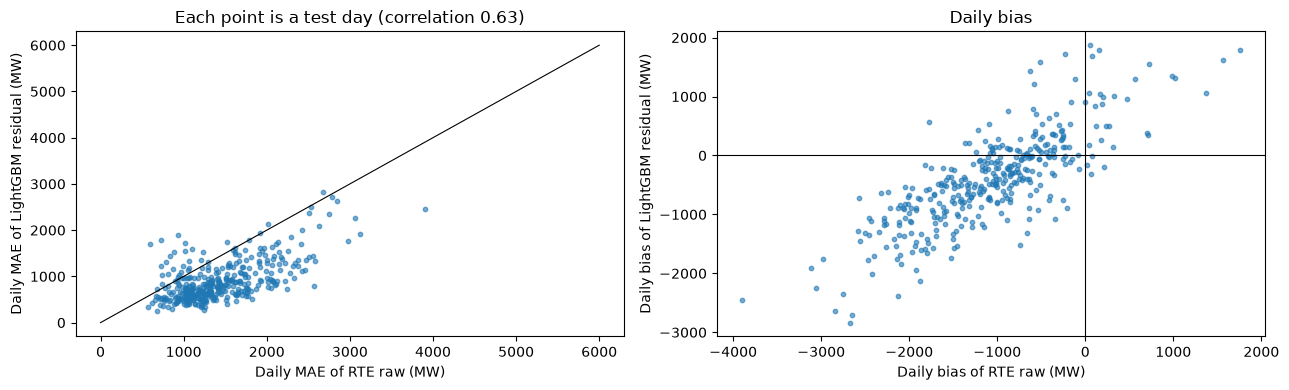

RTE_error_quintile,MAE_RTE_raw,MAE_final,temp_(°C)
enum,f64,f64,f64
"""Q1 (RTE best)""",861.4,753.9,15.8
"""Q2""",1114.7,674.5,14.1
"""Q3""",1326.5,757.9,14.6
"""Q4""",1631.0,948.7,13.0
"""Q5 (RTE worst)""",2243.0,1404.3,12.1


In [20]:
corr_raw = np.corrcoef(daily_errors["MAE_RTE_raw"], daily_errors["MAE_final"])[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(daily_errors["MAE_RTE_raw"], daily_errors["MAE_final"], s=10, alpha=0.6)
ax[0].plot([0, 6000], [0, 6000], color="k", lw=0.8)
ax[0].set_xlabel("Daily MAE of RTE raw (MW)")
ax[0].set_ylabel(f"Daily MAE of {FINAL} (MW)")
ax[0].set_title(f"Each point is a test day (correlation {corr_raw:.2f})")
ax[1].scatter(daily_errors["bias_RTE_raw"], daily_errors["bias_final"], s=10, alpha=0.6)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("Daily bias of RTE raw (MW)")
ax[1].set_ylabel(f"Daily bias of {FINAL} (MW)")
ax[1].set_title("Daily bias")
plt.tight_layout()
plt.show()

quintiles = (
    daily_errors.with_columns(pl.col("MAE_RTE_raw").bin_quantiles(5, labels=["Q1 (RTE best)", "Q2", "Q3", "Q4", "Q5 (RTE worst)"]).alias("RTE_error_quintile"))
    .group_by("RTE_error_quintile")
    .agg(pl.col("MAE_RTE_raw").mean(), pl.col("MAE_final").mean(), pl.col("temp_(°C)").mean())
    .sort("RTE_error_quintile")
)
quintiles.with_columns(pl.exclude("RTE_error_quintile").round(1))

Better than RTE raw in every temperature bin. Error grows in the cold (1,509 to 1,600 MW below 5 °C vs 732 to 822 MW
between 10 and 25 °C) and a bit in the heat (972 MW above 25 °C).

The right plot is the key one: the model's daily bias follows RTE's, shifted by about 1 GW. It removes RTE's usual
error, not its error of the day (daily MAE correlation 0.63, worst quintile 1,404 MW).

### A.8 Order of magnitude for trading

In [21]:
cold_peak = pl.col("evening_peak") & pl.col("cold_day")
energy = pl.DataFrame([
    {
        "forecast": name,
        "total_abs._error_(GWh)": test.select((pl.col(col) - pl.col("target")).abs().sum()).item() / 1000,
        "cold_evening_peaks_(GWh)": test.filter(cold_peak).select((pl.col(col) - pl.col("target")).abs().sum()).item() / 1000,
    }
    for name, col in {"RTE raw": "rte_forecast_j1_mw", f"{FINAL} (final)": FINAL_COL}.items()
]).with_columns((100 * pl.col("cold_evening_peaks_(GWh)") / pl.col("total_abs._error_(GWh)")).alias("share_(%)"))

print(f"cold evening peak hours: {test.filter(cold_peak).height} of {test.height} ({100 * test.filter(cold_peak).height / test.height:.1f} %)")
energy.with_columns(pl.exclude("forecast").round(1))

cold evening peak hours: 81 of 8760 (0.9 %)


forecast,total_abs._error_(GWh),cold_evening_peaks_(GWh),share_(%)
str,f64,f64,f64
"""RTE raw""",12604.0,186.9,1.5
"""LightGBM residual (final)""",7967.7,154.3,1.9


Total absolute error over the test: 12.6 TWh for RTE raw, 8.0 TWh for the final model. Cold evening peaks are 0.9 % of
hours but 1.5 % (RTE raw) and 1.9 % (final) of the error volume, and imbalance prices are highest there.

### A.9 Risks for deployment

RTE publication time. The model needs RTE's D-1 forecast for D+1 before 12:00 on D. Not verified yet, check RTE's
publication calendar. Fallbacks: RTE raw (1,439 MW) if our model breaks, LightGBM persistence (2,010 MW) if RTE is late.

Drift of RTE's error. RTE's bias moved from about -200 MW to about -1,100 MW since 2023, and we still carry about
-420 MW on the test. Retrain regularly and alert if the 7-day mean bias goes beyond, say, ±500 MW.

Consolidated vs real-time data. At 12:00 only the real-time vintage exists and recent lags can be revised (course L4).
Measure the effect on archived real-time data before trusting the 910 MW.

Rare events. Extreme cold (only 3 test days below 0 °C), odd holidays and sudden temperature changes give the worst
days, with intervals too narrow. Keep a manual override and a bigger safety margin on cold days and around holidays.

## Extension: ideas to explore

A rolling debiasing of RTE's forecast, with no training, is tested in extension_rte_debiased.